# Notebook 12: Non-negative CP/PARAFAC — supplementary convergent analysis

The main pipeline takes medians within five lobe-targeted task categories before factorising, which collapses the task dimension. The data are natively four-way: participants × tasks × channels × bands. A non-negative CANDECOMP/PARAFAC decomposition keeps all four modes and yields one factor matrix per mode — A (participants), B (tasks), C (channels), D (bands).

This is run as **supplementary convergent evidence**, not as a replacement pipeline. The question it answers is narrow and worth stating precisely: does a decomposition that never sees the lobe-category aggregation recover the same participant-level sex structure? If it does, the finding is not an artefact of the aggregation choice. If it does not, the aggregation is doing more work than the Methods currently acknowledge.

Because it is supplementary, the primary analysis remains the NMF pipeline and nothing here overwrites those outputs. Two properties of CP make the comparison non-trivial and are handled explicitly below: components are unordered, so they are matched to the NMF solution by cosine similarity on the channel×band outer product; and scale is indeterminate across modes, so factors are normalised before comparison.

**Requires `tensorly`** (`pip install tensorly`).

**Inputs:** `data/eeg_features/BA*/2_emotiv_fft_values.csv`, `data/stimuli.csv`, `outputs/nmf_W.csv`, `outputs/nmf_H.csv`, `outputs/metadata.csv`, `outputs/omnibus_results.csv`

**Outputs:** `outputs/parafac_factors_*.csv`, `outputs/parafac_rank_selection.csv`, `outputs/parafac_omnibus.csv`, `outputs/parafac_posthoc.csv`, `outputs/parafac_task_profiles.csv`, `outputs/parafac_*.png`

## Setup

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy import stats
from scipy.optimize import linear_sum_assignment
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import re
import time
import warnings
warnings.filterwarnings("ignore")

try:
    import tensorly as tl
    from tensorly.decomposition import non_negative_parafac_hals
except ImportError as e:
    raise ImportError("tensorly is required for this notebook: pip install tensorly") from e

PROJECT_ROOT = Path(".").resolve().parent
DATA_DIR = PROJECT_ROOT / "data"
EEG_DIR = DATA_DIR / "eeg_features"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

FREQ_BANDS = ["Theta", "Alpha", "BetaL", "BetaH", "Gamma"]
CHANNELS = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1",
            "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]
POW_COLS = [f"POW.{ch}.{band}" for ch in CHANNELS for band in FREQ_BANDS]

RANK_RANGE = list(range(2, 9))
N_INIT = 10                 # inits per rank for the stability sweep
CHOSEN_RANK = 5             # matched to the NMF k for comparability; revise after the sweep
N_ITER_MAX = 2000
RANDOM_SEED = 42

N_PERMUTATIONS = 5000
FDR_ALPHA = 0.05
N_BOOTSTRAP = 200           # bootstrap refits for the task-profile CIs — the slow part

MISSING_TASK_POLICY = "drop"   # "drop" = keep only fully covered tasks; "impute" = task-mean fill

SEX_COL = "Gender"
SEX_ORDER = ["F", "M"]      # positive effect = higher in females

report = []
def log(msg=""):
    print(msg); report.append(str(msg))
log(f"tensorly version: {tl.__version__}")

tensorly version: 0.9.0


## Build the four-way tensor

For every participant and task, the median across time windows gives a 14 × 5 (channel × band) slice. Values are log-transformed and min–max scaled per (channel, band) across the participant × task plane — the same family of transform as the main pipeline, applied to the mode that survives here — which keeps every entry non-negative, as CP requires.

CP cannot accommodate missing cells, so tasks lacking full coverage are dropped by default. Which tasks these are, and how many participants they lose, is printed: if the count is high, switch `MISSING_TASK_POLICY` to `"impute"` and say so in the Methods.

In [3]:
W_nmf = pd.read_csv(OUTPUT_DIR / "nmf_W.csv", index_col="participant_id")
H_nmf = pd.read_csv(OUTPUT_DIR / "nmf_H.csv", index_col=0)
metadata = pd.read_csv(OUTPUT_DIR / "metadata.csv").set_index("participant_id").reindex(W_nmf.index)
stimuli = pd.read_csv(DATA_DIR / "stimuli.csv")
omnibus_orig = pd.read_csv(OUTPUT_DIR / "omnibus_results.csv")
TASKS_ALL = stimuli["original_stimuli_name"].astype(str).tolist()
sex = metadata[SEX_COL]
PARTICIPANTS = list(W_nmf.index)

def ba_sort_key(p):
    m = re.match(r"BA(\d+)", p.name)
    return int(m.group(1)) if m else 99999

folders = sorted([p for p in EEG_DIR.iterdir() if p.is_dir() and re.match(r"BA\d+", p.name)],
                 key=ba_sort_key)

cube = {}   # (pid, task) -> length-70 vector
for folder in folders:
    pid = folder.name
    if pid not in W_nmf.index:
        continue
    fpath = folder / "2_emotiv_fft_values.csv"
    if not fpath.exists():
        continue
    df = pd.read_csv(fpath)
    if "task_name" not in df.columns or any(c not in df.columns for c in POW_COLS):
        continue
    for task in TASKS_ALL:
        sub = df[df["task_name"] == task]
        if len(sub):
            cube[(pid, task)] = sub[POW_COLS].median().values

coverage = {t: sum((p, t) in cube for p in PARTICIPANTS) for t in TASKS_ALL}
incomplete = {t: n for t, n in coverage.items() if n < len(PARTICIPANTS)}
log(f"Participants: {len(PARTICIPANTS)} | tasks in stimuli.csv: {len(TASKS_ALL)}")
if incomplete:
    log(f"Tasks with incomplete coverage: {incomplete}")
else:
    log("All tasks fully covered.")

if MISSING_TASK_POLICY == "drop":
    TASKS = [t for t in TASKS_ALL if coverage[t] == len(PARTICIPANTS)]
    log(f"Policy 'drop': retaining {len(TASKS)} of {len(TASKS_ALL)} tasks")
else:
    TASKS = [t for t in TASKS_ALL if coverage[t] >= 10]
    log(f"Policy 'impute': retaining {len(TASKS)} tasks, missing cells filled with the task mean")

n_p, n_t, n_c, n_b = len(PARTICIPANTS), len(TASKS), len(CHANNELS), len(FREQ_BANDS)
X = np.full((n_p, n_t, n_c * n_b), np.nan)
for i, pid in enumerate(PARTICIPANTS):
    for j, task in enumerate(TASKS):
        v = cube.get((pid, task))
        if v is not None:
            X[i, j, :] = v

if MISSING_TASK_POLICY != "drop":
    for j in range(n_t):
        slab = X[:, j, :]
        col_means = np.nanmean(slab, axis=0)
        idx = np.where(np.isnan(slab))
        slab[idx] = np.take(col_means, idx[1])
        X[:, j, :] = slab

assert not np.isnan(X).any(), "Tensor still contains missing values"

Xl = np.log1p(X)
flat = Xl.reshape(-1, n_c * n_b)
lo = np.percentile(flat, 2.5, axis=0)
hi = np.percentile(flat, 97.5, axis=0)
flat = np.clip(flat, lo, hi)
mn, mx = flat.min(axis=0), flat.max(axis=0)
rngv = np.where((mx - mn) == 0, 1, (mx - mn))
flat = (flat - mn) / rngv
Xt = flat.reshape(n_p, n_t, n_c, n_b)

log(f"\nTensor shape: {Xt.shape}  (participants × tasks × channels × bands)")
log(f"Range: [{Xt.min():.4f}, {Xt.max():.4f}] — all non-negative: {bool((Xt >= 0).all())}")

Participants: 86 | tasks in stimuli.csv: 37
Tasks with incomplete coverage: {'prefrontal1': 85, 'prefrontal2': 85, 'parietal_2d_3d': 84, 'parietal_next_in_seq': 85, 'temporal_how_many_instruments1': 82, 'temporal_how_many_instruments2': 84, 'temporal_how_many_instruments3': 85, 'temporal_how_many_instruments4': 85, 'image_happy_cute': 85}
Policy 'drop': retaining 28 of 37 tasks

Tensor shape: (86, 28, 14, 5)  (participants × tasks × channels × bands)
Range: [0.0000, 1.0000] — all non-negative: True


## Rank selection by stability

The same logic used for the NMF k sweep: fit each rank from several random initialisations and measure how reproducibly the components come back. Similarity is computed on the concatenated, column-normalised factor matrices and matched across runs with the Hungarian algorithm, so component reordering between runs does not register as instability.

rank= 2 | rel. error 0.4162 | stability 1.0000 ± 0.0000 | 23s
rank= 3 | rel. error 0.3990 | stability 1.0000 ± 0.0000 | 50s
rank= 4 | rel. error 0.3868 | stability 1.0000 ± 0.0000 | 97s
rank= 5 | rel. error 0.3755 | stability 0.9839 ± 0.0189 | 73s
rank= 6 | rel. error 0.3657 | stability 1.0000 ± 0.0000 | 154s
rank= 7 | rel. error 0.3577 | stability 0.9640 ± 0.0253 | 235s
rank= 8 | rel. error 0.3494 | stability 0.9961 ± 0.0077 | 165s


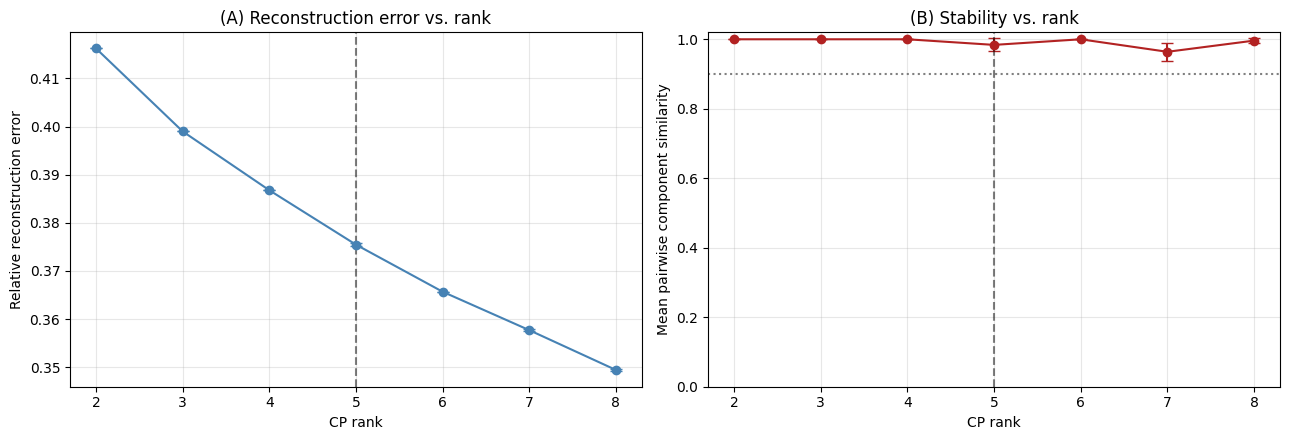


Stability at the chosen rank (5): 0.9839
The rank is matched to the NMF k for comparability. If the sweep favours a different rank,
report both — a convergent analysis that had to be tuned to agree is not convergent.


In [4]:
def fit_cp(tensor, rank, seed):
    cp = non_negative_parafac_hals(tl.tensor(tensor), rank=rank, n_iter_max=N_ITER_MAX,
                                   init="random", random_state=seed, tol=1e-8)
    weights, factors = cp
    return weights, [np.asarray(f) for f in factors]

def normalise_factors(factors):
    """Column-normalise every factor matrix so scale indeterminacy does not affect comparison."""
    out = []
    for F in factors:
        norms = np.linalg.norm(F, axis=0, keepdims=True)
        norms[norms == 0] = 1.0
        out.append(F / norms)
    return out

def signature_matrix(factors):
    """Stack all four normalised factors into one (rank × sum_of_modes) descriptor."""
    nf = normalise_factors(factors)
    return np.hstack([F.T for F in nf])

def cosine_rows(A, B):
    An = A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-12)
    Bn = B / (np.linalg.norm(B, axis=1, keepdims=True) + 1e-12)
    return An @ Bn.T

def match_score(S1, S2):
    sim = cosine_rows(S1, S2)
    r, c = linear_sum_assignment(-sim)
    return sim[r, c].mean()

def reconstruction_error(tensor, weights, factors):
    approx = tl.cp_to_tensor((weights, [tl.tensor(f) for f in factors]))
    return float(np.linalg.norm(tensor - np.asarray(approx)) / np.linalg.norm(tensor))

rank_rows = []
for rank in RANK_RANGE:
    sigs, errs = [], []
    t0 = time.time()
    for i in range(N_INIT):
        w, F = fit_cp(Xt, rank, RANDOM_SEED + i)
        sigs.append(signature_matrix(F))
        errs.append(reconstruction_error(Xt, w, F))
    pair = [match_score(sigs[i], sigs[j]) for i in range(N_INIT) for j in range(i + 1, N_INIT)]
    rank_rows.append({"rank": rank, "mean_rel_error": float(np.mean(errs)),
                      "std_rel_error": float(np.std(errs)),
                      "stability_mean": float(np.mean(pair)), "stability_std": float(np.std(pair)),
                      "seconds": round(time.time() - t0, 1)})
    log(f"rank={rank:2d} | rel. error {np.mean(errs):.4f} | stability {np.mean(pair):.4f} "
        f"± {np.std(pair):.4f} | {time.time() - t0:.0f}s")

rank_df = pd.DataFrame(rank_rows)
rank_df.to_csv(OUTPUT_DIR / "parafac_rank_selection.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].errorbar(rank_df["rank"], rank_df["mean_rel_error"], yerr=rank_df["std_rel_error"],
                 marker="o", capsize=4, color="steelblue")
axes[0].set_xlabel("CP rank"); axes[0].set_ylabel("Relative reconstruction error")
axes[0].set_title("(A) Reconstruction error vs. rank"); axes[0].grid(alpha=0.3)
axes[1].errorbar(rank_df["rank"], rank_df["stability_mean"], yerr=rank_df["stability_std"],
                 marker="o", capsize=4, color="firebrick")
axes[1].axhline(0.9, color="gray", linestyle=":")
axes[1].set_xlabel("CP rank"); axes[1].set_ylabel("Mean pairwise component similarity")
axes[1].set_title("(B) Stability vs. rank"); axes[1].set_ylim(0, 1.02); axes[1].grid(alpha=0.3)
for ax in axes:
    ax.axvline(CHOSEN_RANK, color="black", linestyle="--", alpha=0.5)
    ax.set_xticks(RANK_RANGE)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "parafac_rank_selection.png", dpi=150, bbox_inches="tight")
plt.show()

s_at_rank = rank_df.loc[rank_df["rank"] == CHOSEN_RANK, "stability_mean"].values[0]
log(f"\nStability at the chosen rank ({CHOSEN_RANK}): {s_at_rank:.4f}")
log("The rank is matched to the NMF k for comparability. If the sweep favours a different rank,")
log("report both — a convergent analysis that had to be tuned to agree is not convergent.")

## Fit at the chosen rank and align with the NMF components

In [5]:
errs = []
cands = []
for i in range(N_INIT):
    w, F = fit_cp(Xt, CHOSEN_RANK, RANDOM_SEED + i)
    cands.append((w, F))
    errs.append(reconstruction_error(Xt, w, F))
best = int(np.argmin(errs))
weights, factors = cands[best]
A, B, C, D = factors
log(f"Best of {N_INIT} inits: index {best}, relative error {errs[best]:.4f}")

labels = [f"cp_{i+1}" for i in range(CHOSEN_RANK)]
A_df = pd.DataFrame(A, index=PARTICIPANTS, columns=labels)
B_df = pd.DataFrame(B, index=TASKS, columns=labels)
C_df = pd.DataFrame(C, index=CHANNELS, columns=labels)
D_df = pd.DataFrame(D, index=FREQ_BANDS, columns=labels)
for name, df_ in [("participants", A_df), ("tasks", B_df), ("channels", C_df), ("bands", D_df)]:
    df_.to_csv(OUTPUT_DIR / f"parafac_factors_{name}.csv")

# Align CP components to NMF components via the channel x band outer product,
# compared against the NMF H rows averaged over the five task categories.
def nmf_channel_band_signature(comp):
    row = H_nmf.loc[comp]
    recs = []
    for f, v in row.items():
        _, pow_part = f.split("__", 1)
        _, ch, band = pow_part.split(".")
        recs.append({"channel": ch, "band": band, "loading": v})
    sig = pd.DataFrame(recs).groupby(["channel", "band"])["loading"].mean()
    return np.array([sig.loc[(ch, b)] for ch in CHANNELS for b in FREQ_BANDS])

nmf_sigs = np.vstack([nmf_channel_band_signature(c) for c in H_nmf.index])
cp_sigs = np.vstack([np.outer(C[:, r], D[:, r]).ravel() for r in range(CHOSEN_RANK)])
sim = cosine_rows(cp_sigs, nmf_sigs)
r_ind, c_ind = linear_sum_assignment(-sim)
mapping = pd.DataFrame({
    "cp_component": [labels[i] for i in r_ind],
    "matched_nmf": [H_nmf.index[j] for j in c_ind],
    "cosine_similarity": [sim[i, j] for i, j in zip(r_ind, c_ind)],
}).sort_values("cp_component").reset_index(drop=True)
mapping.to_csv(OUTPUT_DIR / "parafac_component_mapping.csv", index=False)
log("\nCP-to-NMF correspondence (channel × band signature):")
log(mapping.round(4).to_string(index=False))

# Do the CP participant scores track the NMF ones?
corr_rows = []
for _, mrow in mapping.iterrows():
    rho, p = stats.spearmanr(A_df[mrow["cp_component"]], W_nmf[mrow["matched_nmf"]])
    corr_rows.append({"cp_component": mrow["cp_component"], "matched_nmf": mrow["matched_nmf"],
                      "signature_cosine": mrow["cosine_similarity"],
                      "participant_score_rho": float(rho), "p": float(p)})
corr_df = pd.DataFrame(corr_rows)
log("\nParticipant-score agreement between the two decompositions:")
log(corr_df.round(4).to_string(index=False))

Best of 10 inits: index 6, relative error 0.3753

CP-to-NMF correspondence (channel × band signature):
cp_component matched_nmf  cosine_similarity
        cp_1      comp_4             0.9328
        cp_2      comp_3             0.7214
        cp_3      comp_5             0.9505
        cp_4      comp_2             0.9171
        cp_5      comp_1             0.9811

Participant-score agreement between the two decompositions:
cp_component matched_nmf  signature_cosine  participant_score_rho      p
        cp_1      comp_4            0.9328                 0.6817 0.0000
        cp_2      comp_3            0.7214                 0.1770 0.1031
        cp_3      comp_5            0.9505                 0.6813 0.0000
        cp_4      comp_2            0.9171                 0.7373 0.0000
        cp_5      comp_1            0.9811                 0.7786 0.0000


## Omnibus permutation test on the participant factor A

In [6]:
VAR_TYPES = {
    "Age": "continuous", "Gender": "binary",
    "Residential Area (Urban/Rural)": "binary", "From City": "binary",
    "Single/NotSingle": "binary", "Education": "multi", "Field of Study": "multi",
    "Occupation": "multi", "# of LanguagesSpeak": "continuous", "UsedToDoSport": "binary",
    "NowDoingSports_aWeek": "continuous", "PlayingAnInstrument": "binary",
    "History of Neurological Disorders": "binary", "Medication Usage": "binary",
    "Average Sleep Hours per Night": "continuous", "Smoking (0,1,2,3)": "continuous",
    "Alchocol (0,1,2,3)": "continuous",
}
VAR_TYPES = {v: t for v, t in VAR_TYPES.items() if v in metadata.columns}

def log_likelihood_logistic(model, Xm, y):
    proba = np.clip(model.predict_proba(Xm), 1e-12, 1 - 1e-12)
    if proba.shape[1] == 2:
        return np.sum(y * np.log(proba[:, 1]) + (1 - y) * np.log(proba[:, 0]))
    return sum(np.sum(np.log(proba[y == cls, i])) for i, cls in enumerate(model.classes_))

def compute_statistic(Xm, y, vtype):
    if vtype == "continuous":
        return LinearRegression().fit(Xm, y).score(Xm, y)
    if len(np.unique(y)) < 2:
        return np.nan
    try:
        full = LogisticRegression(max_iter=2000, solver="lbfgs").fit(Xm, y)
        ll_full = log_likelihood_logistic(full, Xm, y)
    except Exception:
        return np.nan
    _, counts = np.unique(y, return_counts=True)
    priors = counts / counts.sum()
    ll_null = sum(c * np.log(p) for c, p in zip(counts, priors))
    return np.nan if ll_null == 0 else 1 - (ll_full / ll_null)

rng = np.random.default_rng(RANDOM_SEED)
E = StandardScaler().fit_transform(A_df.values)
rows = []
t0 = time.time()
for var, vtype in VAR_TYPES.items():
    sub = pd.DataFrame({"y": metadata[var]})
    sub["idx"] = np.arange(len(sub))
    sub = sub.dropna()
    if len(sub) < 10:
        rows.append({"variable": var, "type": vtype, "n": len(sub),
                     "observed_stat": np.nan, "p_perm": np.nan}); continue
    Xu = E[sub["idx"].values]
    y_raw = sub["y"].values
    if vtype == "continuous":
        y_use = pd.to_numeric(y_raw, errors="coerce")
        valid = ~pd.isna(y_use)
        Xu, y_use = Xu[valid], y_use[valid].astype(float)
    else:
        y_use, _ = pd.factorize(y_raw)
    obs = compute_statistic(Xu, y_use, vtype)
    if np.isnan(obs):
        rows.append({"variable": var, "type": vtype, "n": len(y_use),
                     "observed_stat": np.nan, "p_perm": np.nan}); continue
    null = np.zeros(N_PERMUTATIONS)
    y_perm = y_use.copy()
    for i in range(N_PERMUTATIONS):
        rng.shuffle(y_perm)
        null[i] = compute_statistic(Xu, y_perm, vtype)
    rows.append({"variable": var, "type": vtype, "n": len(y_use), "observed_stat": obs,
                 "null_mean": float(np.mean(null)), "null_95pct": float(np.percentile(null, 95)),
                 "p_perm": (np.sum(null >= obs) + 1) / (N_PERMUTATIONS + 1)})

parafac_omnibus = pd.DataFrame(rows)
valid = parafac_omnibus["p_perm"].notna()
reject, p_fdr, _, _ = multipletests(parafac_omnibus.loc[valid, "p_perm"],
                                    alpha=FDR_ALPHA, method="fdr_bh")
parafac_omnibus.loc[valid, "p_fdr"] = p_fdr
parafac_omnibus.loc[valid, "significant_fdr"] = reject
parafac_omnibus["significant_fdr"] = parafac_omnibus["significant_fdr"].fillna(False)
parafac_omnibus = parafac_omnibus.sort_values("p_perm").reset_index(drop=True)
parafac_omnibus.to_csv(OUTPUT_DIR / "parafac_omnibus.csv", index=False)
log(f"PARAFAC omnibus ({time.time() - t0:.0f}s):")
log(parafac_omnibus[["variable", "type", "observed_stat", "null_mean", "p_perm", "p_fdr",
                     "significant_fdr"]].round(4).to_string(index=False))

PARAFAC omnibus (278s):
                         variable       type  observed_stat  null_mean  p_perm  p_fdr  significant_fdr
                           Gender     binary         0.1456     0.0445  0.0064 0.1088            False
                        From City     binary         0.3521     0.3003  0.0478 0.2719            False
                              Age continuous         0.1296     0.0586  0.0480 0.2719            False
                        Education      multi         0.1114     0.0768  0.1114 0.4734            False
                       Occupation      multi         0.2680     0.2509  0.2308 0.7846            False
                 Medication Usage     binary         0.1695     0.1360  0.2845 0.8062            False
   Residential Area (Urban/Rural)     binary         0.0821     0.0804  0.4017 0.8605            False
                 Single/NotSingle     binary         0.0509     0.0560  0.4689 0.8605            False
                Smoking (0,1,2,3) continuous     

In [7]:
# Per-component sex tests on A, fixed group order
is_f = (sex == SEX_ORDER[0]).values
rows = []
for comp in labels:
    v = A_df[comp].values
    f, m = v[is_f], v[~is_f]
    u, p = stats.mannwhitneyu(f, m, alternative="two-sided")
    r = 2.0 * u / (len(f) * len(m)) - 1.0
    rows.append({"cp_component": comp, "rank_biserial": r, "p_raw": float(p),
                 "direction": "higher in females" if r > 0 else "higher in males"})
parafac_posthoc = pd.DataFrame(rows)
reject, p_fdr, _, _ = multipletests(parafac_posthoc["p_raw"], alpha=FDR_ALPHA, method="fdr_bh")
parafac_posthoc["p_fdr"] = p_fdr
parafac_posthoc["significant_fdr"] = reject
parafac_posthoc = parafac_posthoc.merge(mapping, left_on="cp_component",
                                        right_on="cp_component", how="left")
parafac_posthoc = parafac_posthoc.sort_values("p_raw").reset_index(drop=True)
parafac_posthoc.to_csv(OUTPUT_DIR / "parafac_posthoc.csv", index=False)
log("Per-component sex tests on the participant factor:")
log(parafac_posthoc[["cp_component", "matched_nmf", "cosine_similarity", "rank_biserial",
                     "direction", "p_raw", "p_fdr", "significant_fdr"]].round(4).to_string(index=False))

Per-component sex tests on the participant factor:
cp_component matched_nmf  cosine_similarity  rank_biserial         direction  p_raw  p_fdr  significant_fdr
        cp_5      comp_1             0.9811         0.2927 higher in females 0.0196 0.0638            False
        cp_2      comp_3             0.7214         0.2803 higher in females 0.0255 0.0638            False
        cp_3      comp_5             0.9505        -0.2338   higher in males 0.0619 0.1032            False
        cp_4      comp_2             0.9171         0.0574 higher in females 0.6501 0.8127            False
        cp_1      comp_4             0.9328         0.0011 higher in females 0.9965 0.9965            False


## Task profiles with bootstrap confidence intervals

Each column of B is a task profile: how strongly each task expresses that component. Confidence intervals come from a participant-level bootstrap — resample participants with replacement, refit the decomposition, and record the task loadings.

Each bootstrap fit is initialised from the full-data solution. This serves two purposes: it converges quickly, and it keeps components in a stable order across resamples. Components are nonetheless re-matched to the full solution by Hungarian assignment on the channel×band signature before their loadings are recorded, because initialisation does not guarantee correspondence.

This is the slow cell. Lower `N_BOOTSTRAP` for a first pass.

In [8]:
from tensorly.cp_tensor import CPTensor

full_sigs = np.vstack([np.outer(C[:, r], D[:, r]).ravel() for r in range(CHOSEN_RANK)])
boot_B = np.full((N_BOOTSTRAP, n_t, CHOSEN_RANK), np.nan)

t0 = time.time()
for b in range(N_BOOTSTRAP):
    idx = rng.choice(n_p, size=n_p, replace=True)
    Xb = Xt[idx]
    try:
        init_cp = CPTensor((tl.tensor(weights.copy()),
                            [tl.tensor(A[idx].copy()), tl.tensor(B.copy()),
                             tl.tensor(C.copy()), tl.tensor(D.copy())]))
        cp_b = non_negative_parafac_hals(tl.tensor(Xb), rank=CHOSEN_RANK,
                                         n_iter_max=500, init=init_cp, tol=1e-7)
        _, Fb = cp_b
        Fb = [np.asarray(f) for f in Fb]
    except Exception:
        continue
    Cb, Db, Bb = Fb[2], Fb[3], Fb[1]
    sigs_b = np.vstack([np.outer(Cb[:, r], Db[:, r]).ravel() for r in range(CHOSEN_RANK)])
    s = cosine_rows(sigs_b, full_sigs)
    ri, ci = linear_sum_assignment(-s)
    order = np.zeros(CHOSEN_RANK, dtype=int)
    for i, j in zip(ri, ci):
        order[j] = i
    Bb_ord = Bb[:, order]
    norms = np.linalg.norm(Bb_ord, axis=0, keepdims=True)
    norms[norms == 0] = 1.0
    boot_B[b] = Bb_ord / norms
    if (b + 1) % 25 == 0:
        log(f"  bootstrap {b + 1}/{N_BOOTSTRAP} ({time.time() - t0:.0f}s)")

n_ok = int((~np.isnan(boot_B[:, 0, 0])).sum())
log(f"\nCompleted bootstrap refits: {n_ok}/{N_BOOTSTRAP}")

B_norm = B / np.where(np.linalg.norm(B, axis=0, keepdims=True) == 0, 1,
                      np.linalg.norm(B, axis=0, keepdims=True))
rows = []
for r, comp in enumerate(labels):
    lo = np.nanpercentile(boot_B[:, :, r], 2.5, axis=0)
    hi = np.nanpercentile(boot_B[:, :, r], 97.5, axis=0)
    for j, task in enumerate(TASKS):
        rows.append({"cp_component": comp, "task": task,
                     "loading": float(B_norm[j, r]),
                     "ci_lo": float(lo[j]), "ci_hi": float(hi[j])})
task_profiles = pd.DataFrame(rows)
task_profiles.to_csv(OUTPUT_DIR / "parafac_task_profiles.csv", index=False)
log("Saved parafac_task_profiles.csv")

  bootstrap 25/200 (87s)
  bootstrap 50/200 (205s)
  bootstrap 75/200 (330s)
  bootstrap 100/200 (440s)
  bootstrap 125/200 (552s)
  bootstrap 150/200 (662s)
  bootstrap 175/200 (775s)
  bootstrap 200/200 (884s)

Completed bootstrap refits: 200/200
Saved parafac_task_profiles.csv


## Figures

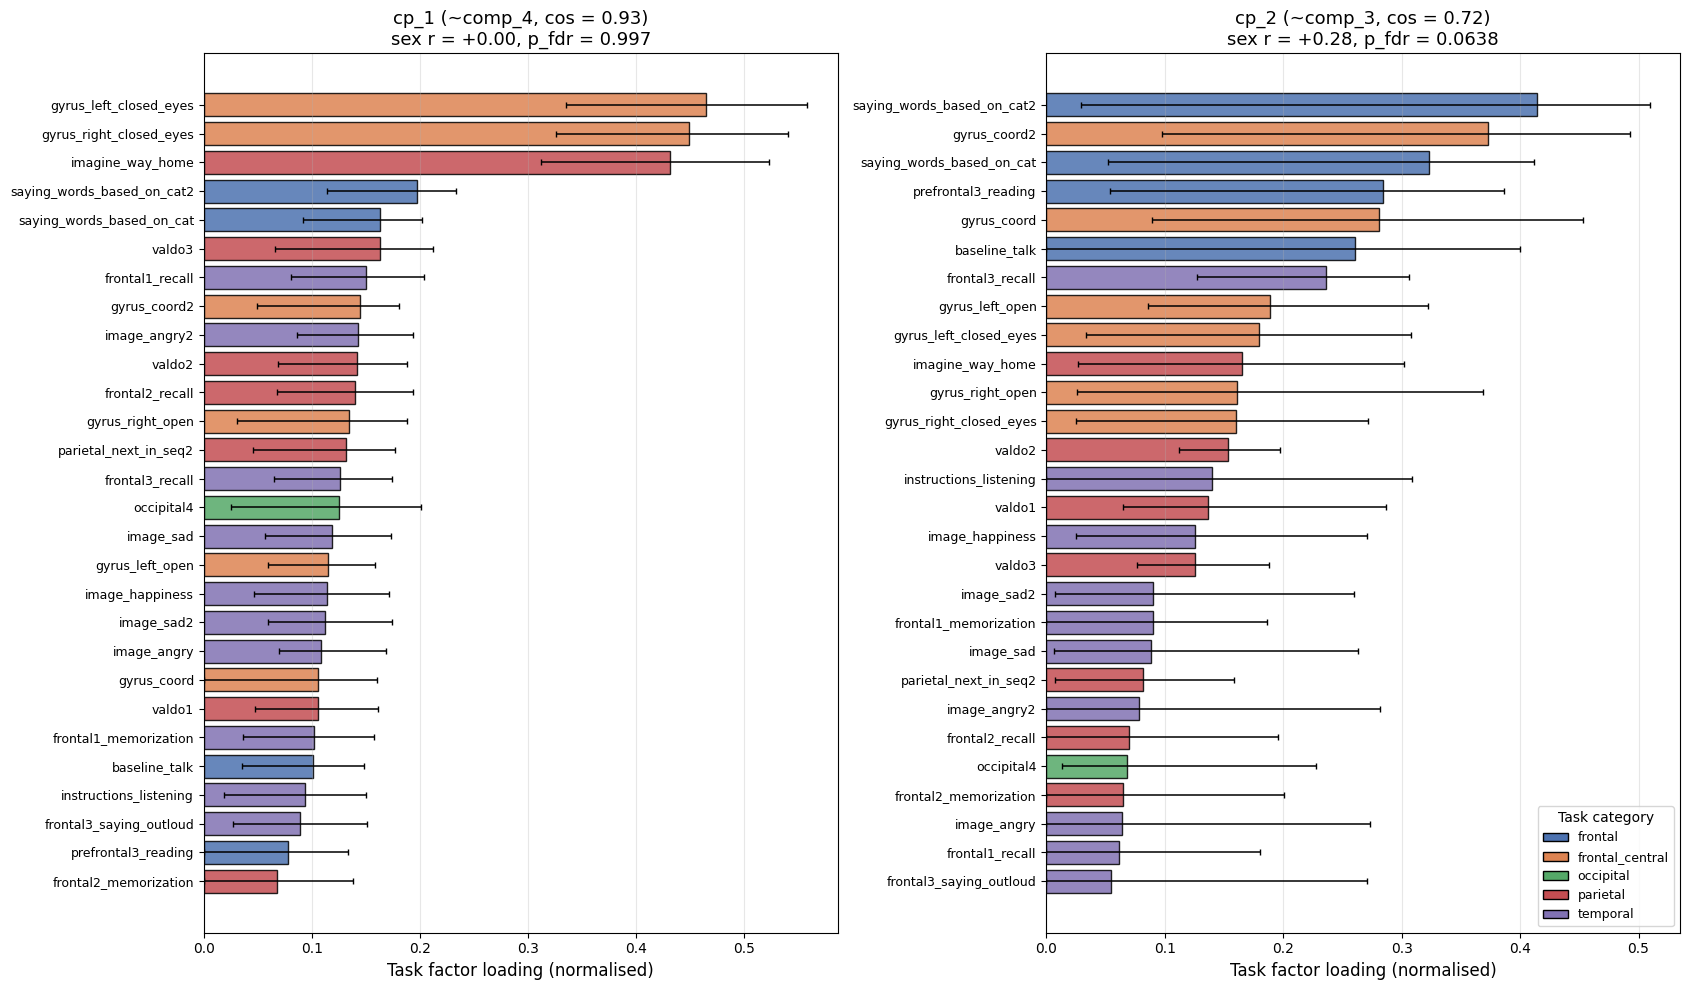

In [9]:
task2cat = dict(zip(stimuli["original_stimuli_name"], stimuli["primary_lobe_targeted"]))
def norm_cat(c):
    return str(c).strip().lower().replace("-", "_").replace(" ", "_")
CATEGORY_COLOURS = {"frontal": "#4C72B0", "frontal_central": "#DD8452", "occipital": "#55A868",
                    "parietal": "#C44E52", "temporal": "#8172B3"}

sex_comps = parafac_posthoc[parafac_posthoc["significant_fdr"]]["cp_component"].tolist()
show = sex_comps if sex_comps else labels[:2]

fig, axes = plt.subplots(1, len(show), figsize=(8.5 * len(show), 10), squeeze=False)
for ax, comp in zip(axes[0], show):
    sub = task_profiles[task_profiles["cp_component"] == comp].sort_values("loading")
    colours = [CATEGORY_COLOURS.get(norm_cat(task2cat.get(t)), "#999999") for t in sub["task"]]
    y = np.arange(len(sub))
    ax.barh(y, sub["loading"], color=colours, edgecolor="black", alpha=0.85)
    ax.errorbar(sub["loading"], y,
                xerr=[np.maximum(sub["loading"] - sub["ci_lo"], 0),
                      np.maximum(sub["ci_hi"] - sub["loading"], 0)],
                fmt="none", ecolor="black", elinewidth=1.1, capsize=2.5)
    ax.set_yticks(y); ax.set_yticklabels(sub["task"], fontsize=9)
    ax.set_xlabel("Task factor loading (normalised)", fontsize=12)
    row = parafac_posthoc[parafac_posthoc["cp_component"] == comp].iloc[0]
    ax.set_title(f"{comp} (~{row['matched_nmf']}, cos = {row['cosine_similarity']:.2f})\n"
                 f"sex r = {row['rank_biserial']:+.2f}, p_fdr = {row['p_fdr']:.3g}", fontsize=13)
    ax.grid(alpha=0.3, axis="x")
from matplotlib.patches import Patch
axes[0][-1].legend(handles=[Patch(facecolor=c, edgecolor="black", label=k)
                            for k, c in CATEGORY_COLOURS.items()],
                   title="Task category", loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "parafac_task_profiles.png", dpi=200, bbox_inches="tight")
plt.show()

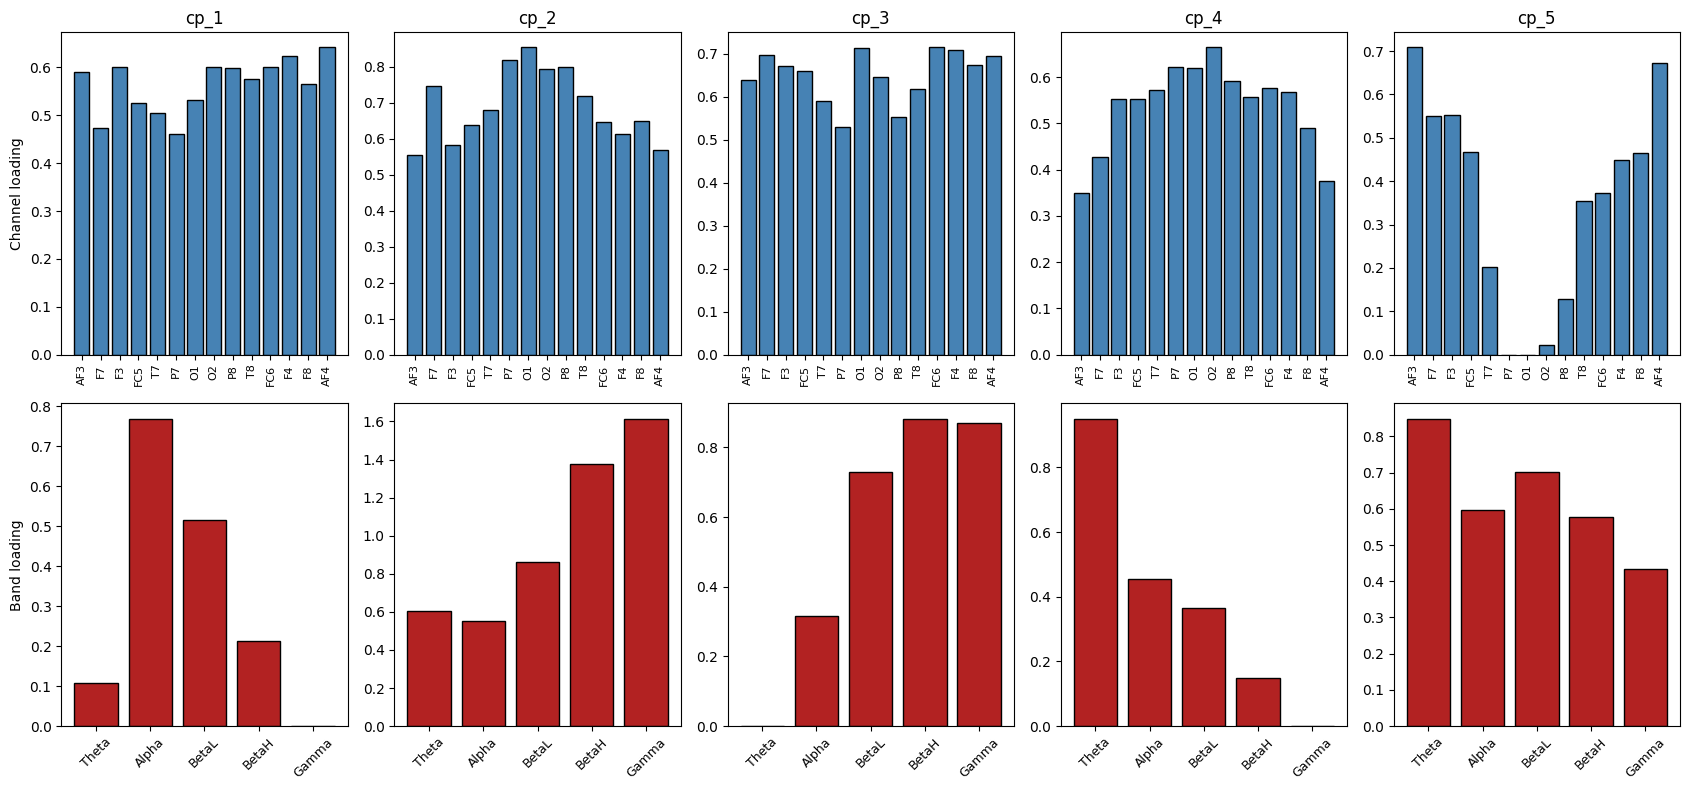

In [10]:
fig, axes = plt.subplots(2, CHOSEN_RANK, figsize=(3.4 * CHOSEN_RANK, 8))
for r, comp in enumerate(labels):
    ax = axes[0, r]
    ax.bar(CHANNELS, C[:, r], color="steelblue", edgecolor="black")
    ax.set_title(comp, fontsize=12)
    ax.tick_params(axis="x", rotation=90, labelsize=8)
    if r == 0:
        ax.set_ylabel("Channel loading")
    ax = axes[1, r]
    ax.bar(FREQ_BANDS, D[:, r], color="firebrick", edgecolor="black")
    ax.tick_params(axis="x", rotation=45, labelsize=9)
    if r == 0:
        ax.set_ylabel("Band loading")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "parafac_channel_band_factors.png", dpi=200, bbox_inches="tight")
plt.show()

## Verdict

In [11]:
nmf_sex = omnibus_orig[omnibus_orig["variable"] == SEX_COL].iloc[0]
cp_sex = parafac_omnibus[parafac_omnibus["variable"] == SEX_COL].iloc[0]

log("\n" + "=" * 78)
log("PARAFAC SUPPLEMENTARY ANALYSIS — VERDICT")
log("=" * 78)
log(f"\nTensor:        {Xt.shape}, policy '{MISSING_TASK_POLICY}', rank {CHOSEN_RANK}")
log(f"NMF omnibus for sex:     stat = {nmf_sex['observed_stat']:.4f}, p_fdr = {nmf_sex['p_fdr']:.4f}")
log(f"PARAFAC omnibus for sex: stat = {cp_sex['observed_stat']:.4f}, p_fdr = {cp_sex['p_fdr']:.4f}")

cp_sig_vars = parafac_omnibus[parafac_omnibus["significant_fdr"]]["variable"].tolist()
log(f"\nVariables surviving FDR under PARAFAC: {cp_sig_vars if cp_sig_vars else 'none'}")
log(f"Components carrying sex: "
    f"{parafac_posthoc[parafac_posthoc['significant_fdr']]['cp_component'].tolist()}")

if bool(cp_sex["significant_fdr"]):
    log("\n  The sex association is recovered by a decomposition that never sees the lobe-category")
    log("  aggregation. The finding is therefore not an artefact of that aggregation choice.")
    log("  Report this as a supplementary convergent analysis, with the component correspondence")
    log("  table, and keep the NMF pipeline as the primary result.")
    strong = corr_df[corr_df["signature_cosine"] > 0.8]
    log(f"\n  Components matching the NMF solution at cosine > 0.8: {len(strong)} of {CHOSEN_RANK}")
    if len(strong) == 0:
        log("  [CHECK] Convergence holds at the level of the sex association but not at the level")
        log("          of the components themselves. Say that precisely — it is a weaker and")
        log("          different claim from 'the same components were recovered'.")
else:
    log("\n  The sex association is NOT recovered by the tensor decomposition. This does not")
    log("  invalidate the NMF result, but it does mean the finding depends on the aggregation")
    log("  step, and that dependence has to be reported rather than filed away as a negative")
    log("  supplementary result. Discuss with Mateo how much weight the main claim can bear.")

log("\nFiles saved:")
for f in ["parafac_rank_selection.csv", "parafac_factors_participants.csv",
          "parafac_factors_tasks.csv", "parafac_factors_channels.csv",
          "parafac_factors_bands.csv", "parafac_component_mapping.csv",
          "parafac_omnibus.csv", "parafac_posthoc.csv", "parafac_task_profiles.csv",
          "parafac_rank_selection.png", "parafac_task_profiles.png",
          "parafac_channel_band_factors.png", "parafac_summary.txt"]:
    log(f"  {f}")
with open(OUTPUT_DIR / "parafac_summary.txt", "w", encoding="utf-8") as fh:
    fh.write("\n".join(report))


PARAFAC SUPPLEMENTARY ANALYSIS — VERDICT

Tensor:        (86, 28, 14, 5), policy 'drop', rank 5
NMF omnibus for sex:     stat = 0.2742, p_fdr = 0.0034
PARAFAC omnibus for sex: stat = 0.1456, p_fdr = 0.1088

Variables surviving FDR under PARAFAC: none
Components carrying sex: []

  The sex association is NOT recovered by the tensor decomposition. This does not
  invalidate the NMF result, but it does mean the finding depends on the aggregation
  step, and that dependence has to be reported rather than filed away as a negative
  supplementary result. Discuss with Mateo how much weight the main claim can bear.

Files saved:
  parafac_rank_selection.csv
  parafac_factors_participants.csv
  parafac_factors_tasks.csv
  parafac_factors_channels.csv
  parafac_factors_bands.csv
  parafac_component_mapping.csv
  parafac_omnibus.csv
  parafac_posthoc.csv
  parafac_task_profiles.csv
  parafac_rank_selection.png
  parafac_task_profiles.png
  parafac_channel_band_factors.png
  parafac_summary.txt


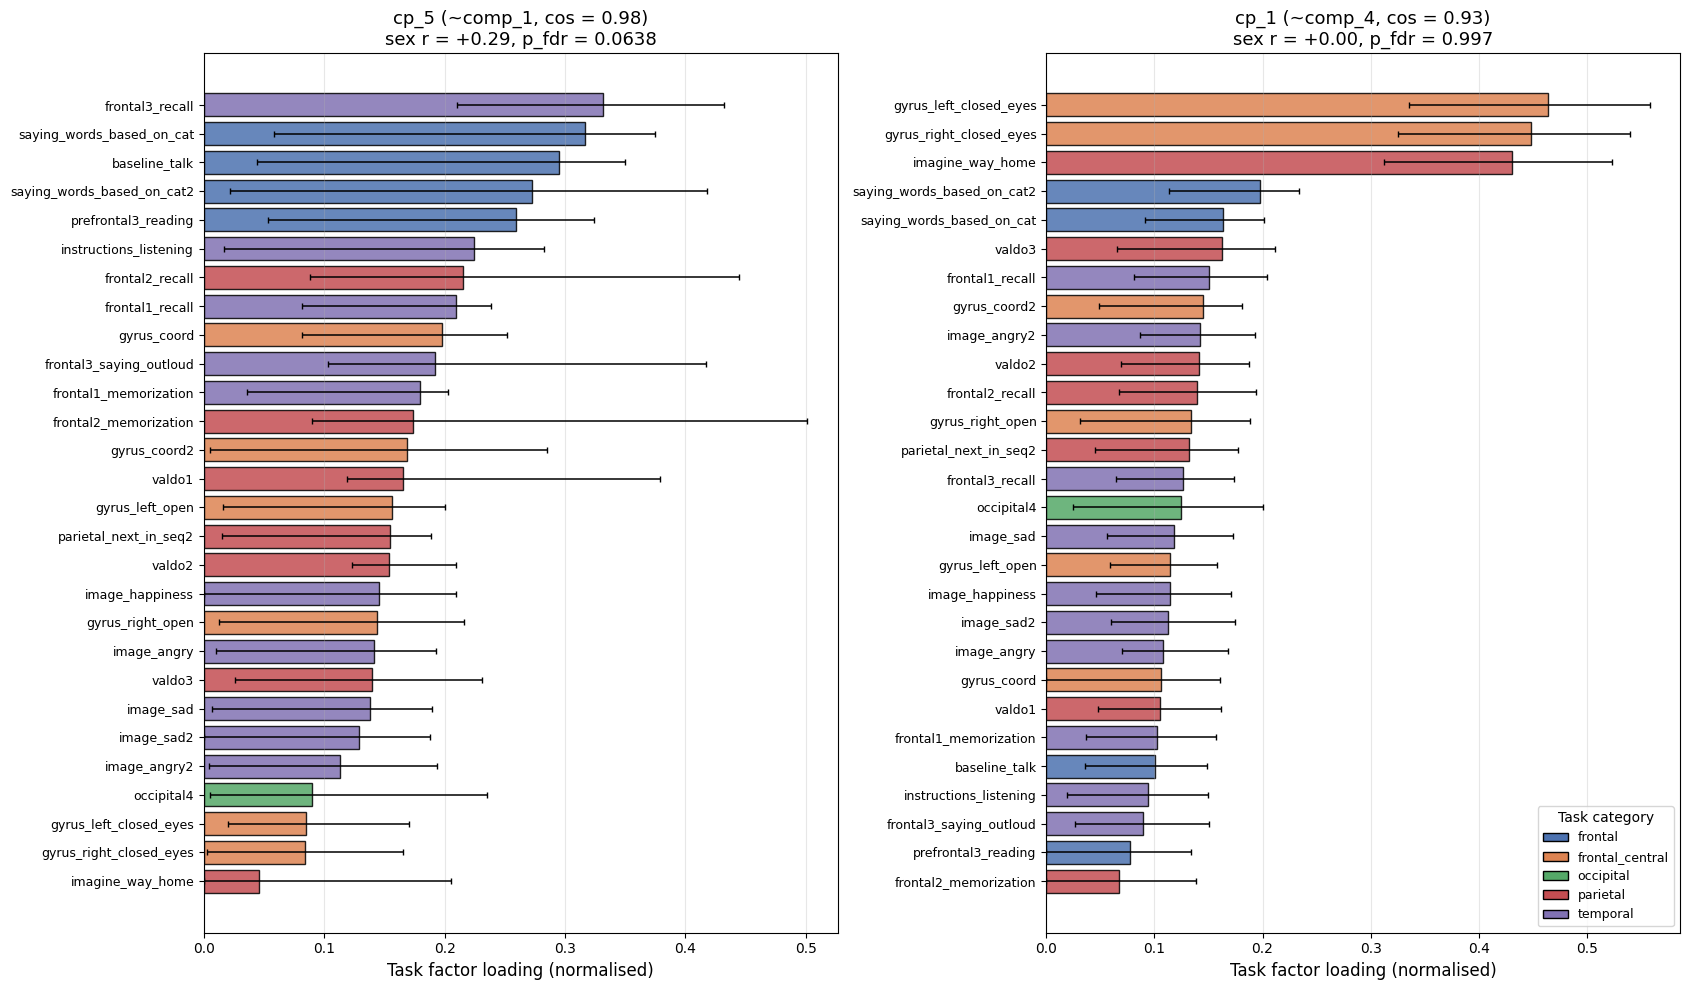

Wrote C:\Users\lukab\Desktop\Algebra EEG\Project NMF\outputs\parafac_task_profiles.png
Components plotted: ['cp_5', 'cp_1']


In [2]:
"""Regenerate the PARAFAC task-profile figure (Supplementary Figure 6) from saved CSVs.

Standalone: needs no kernel state from notebook 12. Run from the notebooks directory,
or edit PROJECT_ROOT below.

Reads   outputs/parafac_task_profiles.csv
        outputs/parafac_posthoc.csv
        data/stimuli.csv
Writes  outputs/parafac_task_profiles.png
"""

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

PROJECT_ROOT = Path(".").resolve().parent
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

# cp_5 is the comp_1 analogue, cp_1 the comp_4 analogue — this is the fix.
SHOW = ["cp_5", "cp_1"]

CATEGORY_COLOURS = {"frontal": "#4C72B0", "frontal_central": "#DD8452", "occipital": "#55A868",
                    "parietal": "#C44E52", "temporal": "#8172B3"}

task_profiles = pd.read_csv(OUTPUT_DIR / "parafac_task_profiles.csv")
posthoc = pd.read_csv(OUTPUT_DIR / "parafac_posthoc.csv")
stimuli = pd.read_csv(DATA_DIR / "stimuli.csv")

missing = [c for c in SHOW if c not in set(task_profiles["cp_component"])]
if missing:
    raise ValueError(f"Components {missing} not in parafac_task_profiles.csv; "
                     f"available: {sorted(set(task_profiles['cp_component']))}")

task2cat = dict(zip(stimuli["original_stimuli_name"], stimuli["primary_lobe_targeted"]))
def norm_cat(c):
    return str(c).strip().lower().replace("-", "_").replace(" ", "_")

fig, axes = plt.subplots(1, len(SHOW), figsize=(8.5 * len(SHOW), 10), squeeze=False)

for ax, comp in zip(axes[0], SHOW):
    sub = task_profiles[task_profiles["cp_component"] == comp].sort_values("loading")
    colours = [CATEGORY_COLOURS.get(norm_cat(task2cat.get(t)), "#999999") for t in sub["task"]]
    y = np.arange(len(sub))
    ax.barh(y, sub["loading"], color=colours, edgecolor="black", alpha=0.85)
    ax.errorbar(sub["loading"], y,
                xerr=[np.maximum(sub["loading"] - sub["ci_lo"], 0),
                      np.maximum(sub["ci_hi"] - sub["loading"], 0)],
                fmt="none", ecolor="black", elinewidth=1.1, capsize=2.5)
    ax.set_yticks(y)
    ax.set_yticklabels(sub["task"], fontsize=9)
    ax.set_xlabel("Task factor loading (normalised)", fontsize=12)

    row = posthoc[posthoc["cp_component"] == comp]
    if len(row):
        row = row.iloc[0]
        ax.set_title(f"{comp} (~{row['matched_nmf']}, cos = {row['cosine_similarity']:.2f})\n"
                     f"sex r = {row['rank_biserial']:+.2f}, p_fdr = {row['p_fdr']:.3g}",
                     fontsize=13)
    else:
        ax.set_title(comp, fontsize=13)
    ax.grid(alpha=0.3, axis="x")

axes[0][-1].legend(handles=[Patch(facecolor=c, edgecolor="black", label=k)
                            for k, c in CATEGORY_COLOURS.items()],
                   title="Task category", loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "parafac_task_profiles.png", dpi=200, bbox_inches="tight")
plt.show()
print("Wrote", OUTPUT_DIR / "parafac_task_profiles.png")
print("Components plotted:", SHOW)